In [3]:
%pylab inline
import os
import catutil
import astropy.io.fits as pyfits
import pltutil

Populating the interactive namespace from numpy and matplotlib


In [4]:
datDir='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_others/'
pltDir='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/psfTest/'
datDir2='wrkDir/s19/s19-pre/psf_test_from_wentao/results/'

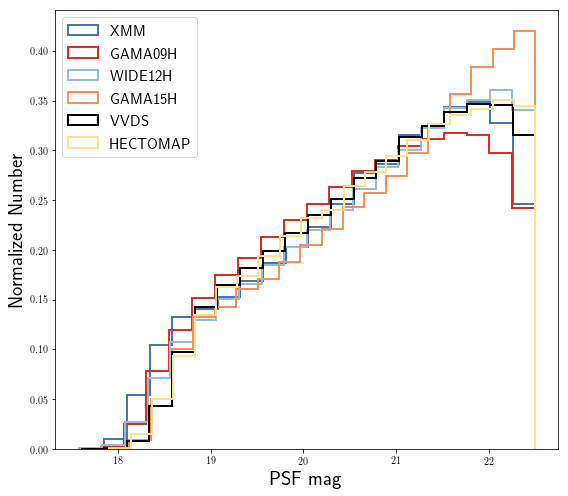

In [5]:
plt.close()
fig=plt.figure(figsize=(8,7))
ax=fig.add_subplot(1,1,1)
for fieldname in catutil.field_names:
    fname='%s_star.fits'%fieldname
    fname=os.path.join(datDir,fname)
    data=pyfits.getdata(fname)
    data=data[data['i_calib_psf_used']]
    mag=data['i_psfflux_mag']
    ax.hist(mag,bins=20,color=pltutil.plot_colors[fieldname],histtype='step',density=True,\
            linewidth=2.,label=fieldname)
    ax.set_xlabel(r'PSF mag ', fontsize=20)
    ax.set_ylabel('Normalized Number',fontsize=20)
plt.legend(fontsize=15,loc='upper left')
plt.tight_layout()
fig.savefig(os.path.join(pltDir,'psf_mag_dis2.eps'))

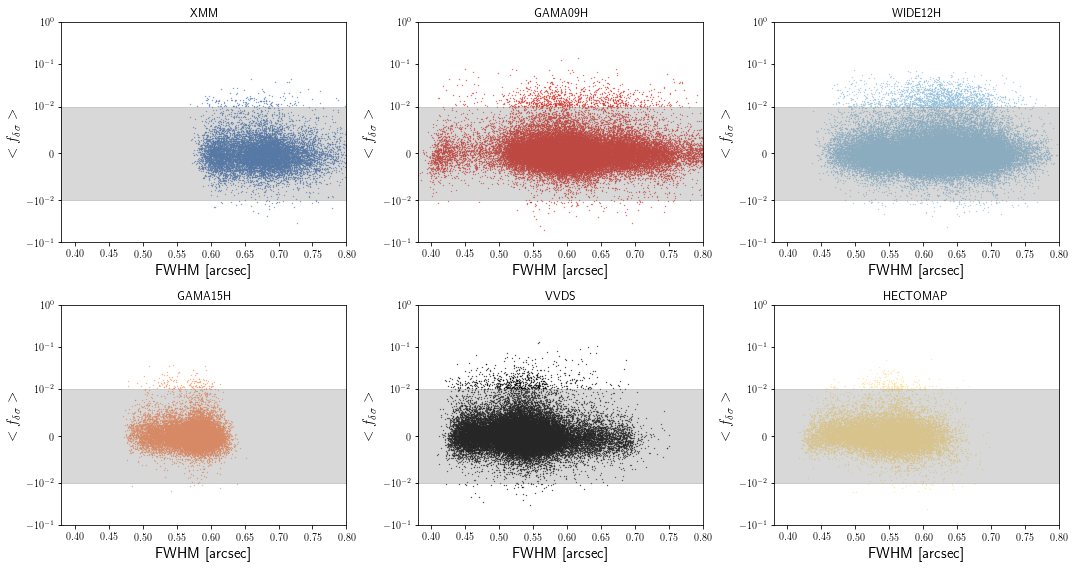

In [46]:
plt.close()
bandx   = [0.38,0.8]
bandyp  = [0.01,0.01]
bandyn  = [-0.01,-0.01]
fig = plt.figure(figsize=(15,8))
fig.set_rasterized(True) 
ip=0
for fieldname in catutil.field_names:
    ip+=1
    fnt2,sgt2 = np.loadtxt(datDir2+'%s_healpy_cuts.dat'%fieldname,unpack=True)
    idx     = np.abs(fnt2)<=10.02
    fn2     = fnt2[idx]
    sg2     = sgt2[idx]

    ax=fig.add_subplot(2,3,ip)
    ax.scatter(sg2,fn2,s=0.1,color=pltutil.plot_colors[fieldname])
    ax.fill_between(bandx,bandyp,bandyn,alpha=0.3,color='grey')
    ax.set_xlim(0.38,0.8)
    ax.set_ylim(-0.1,1)
    ax.set_yscale('symlog',linthreshy=0.01)
    ax.set_title(fieldname)
    ax.set_xlabel(r'FWHM [arcsec]',fontsize=15)
    ax.set_ylabel(r'$<f_{\delta\sigma}>$',fontsize=15)
    ax.set_rasterized(True)
plt.tight_layout()
fig.savefig(os.path.join(pltDir,'psf_test_healpix.eps'),rasterized=True,dpi=100)